# Massachusetts context: where would last-minute slots actually get filled?

Supporting analysis for Hackachusetts **H3: Improving healthcare access and coordination** ("a referral is not a finished visit").

**Data**
- **Synthea**: 3,000 living synthetic Massachusetts residents (MITRE's open-source patient generator, Apache-2.0). Synthea places people in towns by census population, with ages, insurance, conditions and visit histories. **None of these are real people.** Regenerate with `synthea/generate.sh`.
- **MassGIS / MA Department of Public Health**: 103 licensed hospitals with locations and bed counts (70 acute).
- **Synthea's Massachusetts primary-care site list** (456 sites).

**Questions**
1. How far do residents live from care, by county?
2. How many people live close enough to fill a last-minute slot, in Boston vs rural Franklin County?
3. What does that do to the refill rate from notebook 01?

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parent / "src"))
import massachusetts as ma
plt.rcParams.update({"figure.figsize": (7, 3.8), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.2f}".format)

residents, hospitals, sites = ma.load_tables()
print(f"{len(residents):,} synthetic residents · {len(hospitals)} hospitals ({(hospitals.type == 'Acute Hospital').sum()} acute) · {len(sites)} primary-care sites")
residents[["first_name", "age", "gender", "city", "county", "insurance", "primary_visits_last_year"]].head()

3,000 synthetic residents · 103 hospitals (70 acute) · 456 primary-care sites


,first_name,age,gender,city,county,insurance,primary_visits_last_year
0,Hayden,49,M,Norwood,Norfolk,Medicaid,1
1,Jacinto,70,M,Worcester,Worcester,Medicare,2
2,Donny,55,M,Stoneham,Middlesex,Aetna,3
3,Hoa,20,F,Cambridge,Middlesex,Cigna Health,1
4,Dixie,37,F,Charlton,Worcester,Humana,8


Synthea spreads residents across counties roughly in proportion to real population:

In [2]:
residents.county.value_counts().to_frame("synthetic_residents").T

county,Middlesex,Worcester,Suffolk,Norfolk,Essex,Bristol,Plymouth,Hampden,Barnstable,Hampshire,Berkshire,Franklin,Dukes,Nantucket
synthetic_residents,728,358,345,304,301,237,226,215,120,71,56,22,11,6


## 1. Distance to care, by county
For every synthetic resident: straight-line miles to the nearest acute hospital and nearest primary-care site.

In [3]:
access = ma.access_by_county(residents, hospitals, sites)
access

,synthetic_residents,median_miles_to_hospital,share_over_10mi_from_hospital,median_miles_to_primary_care
county,,,,
Barnstable,120,6.95,0.23,2.42
Franklin,22,6.35,0.09,3.68
Hampshire,71,5.53,0.07,2.69
Plymouth,226,5.53,0.17,2.82
Dukes,11,5.43,0.27,3.99
Worcester,358,4.44,0.07,2.62
Bristol,237,4.24,0.00,2.75
Norfolk,304,3.88,0.03,1.42
Berkshire,56,3.85,0.04,2.61


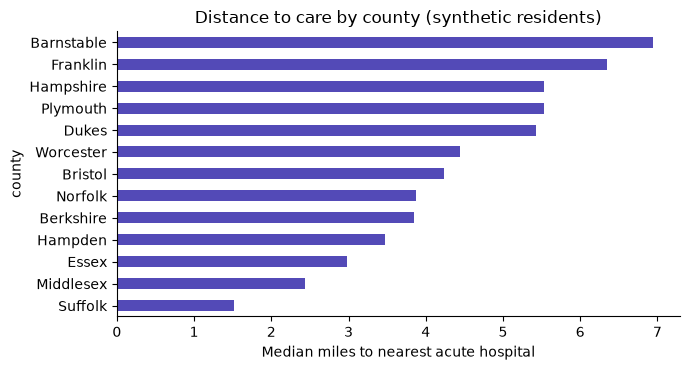

In [4]:
a = access[access.synthetic_residents >= 10].sort_values("median_miles_to_hospital")
ax = a.median_miles_to_hospital.plot.barh(color="#534AB7")
ax.set_xlabel("Median miles to nearest acute hospital"); ax.set_title("Distance to care by county (synthetic residents)")
plt.tight_layout(); plt.show()

Nantucket (6 synthetic residents) is left off the chart; small counties such as Franklin (22) and Dukes (11) are shown but noisy. Straight-line distance also understates rural travel: roads are longer and transit is thinner.

## 2. Who lives close enough to fill a last-minute slot?
Residents within each radius of a Boston clinic (Kenmore Square) and a rural one (Greenfield), scaled from the synthetic sample to the 2020 Census population.

In [5]:
est = ma.standby_estimates(residents)
rows = []
for k, e in est.items():
    for r, v in e["residents_within"].items():
        rows.append({"place": e["label"], "radius_mi": r, "synthetic_residents": v["synthetic"], "estimated_residents": v["estimated_residents"], "standby_patients": e["standby_patients_within"][r]})
density = pd.DataFrame(rows).pivot(index="radius_mi", columns="place", values=["estimated_residents", "standby_patients"])
density

estimated_residents                           standby_patients  \
place        Boston (Kenmore) Greenfield (Franklin Co.) Boston (Kenmore)   
radius_mi                                                                  
1                    46866.00                   2343.00             0.80   
2                   175748.00                   7030.00             3.00   
4                   691275.00                  11717.00            11.80   
8                  1572358.00                  28120.00            26.84   
16                 2638562.00                  98419.00            45.04   

                                     
place     Greenfield (Franklin Co.)  
radius_mi                            
1                              0.04  
2                              0.12  
4                              0.20  
8                              0.48  
16                             1.68

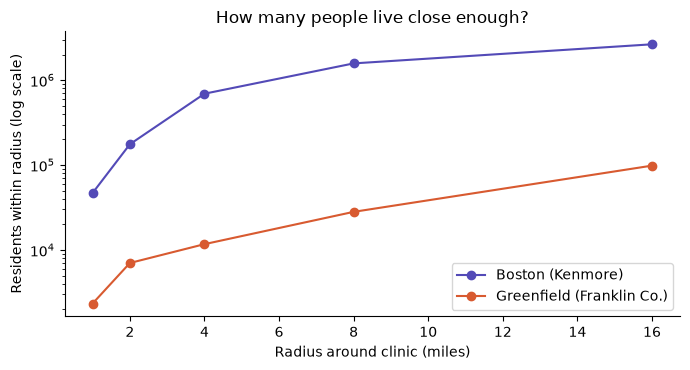

In [6]:
for k, color in (("boston", "#534AB7"), ("rural", "#D85A30")):
    radii = sorted(est[k]["residents_within"])
    plt.plot(radii, [est[k]["residents_within"][r]["estimated_residents"] for r in radii], "o-", color=color, label=est[k]["label"])
plt.yscale("log"); plt.xlabel("Radius around clinic (miles)"); plt.ylabel("Residents within radius (log scale)")
plt.title("How many people live close enough?"); plt.legend(); plt.tight_layout(); plt.show()

**How the standby estimate works:** notebook 01 assumed about 3 eligible standby patients within reach of a clinic. We anchor that assumption to a **Boston clinic at 2 miles**, then scale every other place and radius by how many people live there. It's one assumption plus real population geography, not a new guess per town.

Rural counts rest on few synthetic residents (see the `synthetic_residents` column), so treat them as order-of-magnitude. Run Synthea with more people for tighter numbers.

## 3. What that does to the refill rate
Same model, same 20% outreach budget as notebook 01, but with each place's standby supply. 8 miles is the radius after the app's ripple (2 mi, doubled twice).

In [7]:
test, p = ma.test_predictions()
fills = ma.fill_by_place(est, test, p)
pd.DataFrame([{"place": est[k]["label"], "radius_mi": r, **v} for k in fills for r, v in fills[k].items()])

,place,radius_mi,standby_patients,fill_probability,fill_rate_model
0,Boston (Kenmore),2,3.00,0.65,0.22
1,Boston (Kenmore),8,26.84,1.00,0.34
2,Greenfield (Franklin Co.),2,0.12,0.04,0.01
3,Greenfield (Franklin Co.),8,0.48,0.15,0.05


In [8]:
m = json.loads((ma.ARTIFACTS / "metrics.json").read_text())["massachusetts"]
b, r = m["boston"], m["rural"]
print(f"Boston: ~{b['residents_within_2mi']:,} residents within 2 mi -> {b['fill']['2']['fill_rate_model']:.0%} of no-show slots refilled "
      f"({b['fill']['8']['fill_rate_model']:.0%} with ripple to 8 mi).")
print(f"Greenfield: ~{r['residents_within_2mi']:,} residents within 2 mi -> {r['fill']['2']['fill_rate_model']:.1%} refilled "
      f"({r['fill']['8']['fill_rate_model']:.1%} with ripple to 8 mi).")

Boston: ~175,748 residents within 2 mi -> 22% of no-show slots refilled (34% with ripple to 8 mi).
Greenfield: ~7,030 residents within 2 mi -> 1.4% refilled (5.3% with ripple to 8 mi).


## Takeaways for the pitch
- **The same system works very differently by geography.** In Boston, a 2-mile standby list refills about a fifth of no-show slots. In Franklin County the same rule barely works, because about 25× fewer people live within 2 miles.
- **That's why the radius ripples.** Widening the radius helps everywhere, and it's the only option in rural areas.
- **The rural fix is time, not just distance.** Rural clinics should release high-risk slots earlier (hours, not 30 minutes) so people farther away can make it, or offer the slot as a telehealth visit. That's a direct H3 recommendation.

**Caveats**
- Synthetic residents are not real people; Synthea follows census town populations but not exact addresses.
- Distances are straight-line, not drive time.
- Standby supply scales one anchored assumption by density; it's not a measured opt-in rate.